In [1]:
import os
import random
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

# =========================
# CONFIG
# =========================
SEED = 42

ROOT = r"D:\gpt\OcuVision-AI"
DATA_DIR = os.path.join(ROOT, "data", "preprocessed")
RESULTS_DIR = os.path.join(ROOT, "results", "inception_v3")
CHECKPOINT_PATH = os.path.join(
    ROOT, "models", "inception_v3_best_checkpoint.pth"
)

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(os.path.dirname(CHECKPOINT_PATH), exist_ok=True)

CLASSES = ["N", "D", "G", "C", "A", "H", "M"]
NUM_CLASSES = len(CLASSES)

IMAGE_SIZE = 299
BATCH_SIZE = 16
NUM_EPOCHS = 5
LR = 1e-4
WEIGHT_DECAY = 1e-4

# =========================
# REPRODUCIBILITY
# =========================
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# =========================
# COLLECT IMAGE PATHS
# =========================
image_paths = []
labels = []

for class_idx, class_name in enumerate(CLASSES):
    class_dir = os.path.join(DATA_DIR, class_name)

    files = [
        os.path.join(class_dir, f)
        for f in os.listdir(class_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"))
    ]

    print(f"{class_name}: {len(files)} images")

    image_paths.extend(files)
    labels.extend([class_idx] * len(files))

image_paths = np.array(image_paths)
labels = np.array(labels)

print("\nTotal images:", len(image_paths))

# =========================
# 80 / 10 / 10 STRATIFIED SPLIT
# =========================
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    stratify=labels,
    random_state=SEED
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=SEED
)

print("\nSplit sizes:")
print("Train:", len(train_paths))
print("Validation:", len(val_paths))
print("Test:", len(test_paths))

assert len(train_paths) == 8359
assert len(val_paths) == 1045
assert len(test_paths) == 1045

# =========================
# DATASET
# =========================
class ODIRDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert("RGB")
        label = int(self.labels[idx])

        if self.transform:
            image = self.transform(image)

        return image, label

# =========================
# TRANSFORMS
# =========================
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = ODIRDataset(train_paths, train_labels, train_transform)
val_dataset = ODIRDataset(val_paths, val_labels, eval_transform)
test_dataset = ODIRDataset(test_paths, test_labels, eval_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("\nDataLoaders ready.")
print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Test batches:", len(test_loader))

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
N: 2997 images
D: 3128 images
G: 1646 images
C: 1008 images
A: 511 images
H: 420 images
M: 739 images

Total images: 10449

Split sizes:
Train: 8359
Validation: 1045
Test: 1045

DataLoaders ready.
Train batches: 523
Val batches: 66
Test batches: 66


Model: InceptionV3
Device: cuda
Trainable parameters: 24362990


Epoch 1/5 [Train]:   0%|          | 0/523 [00:00<?, ?it/s]

Epoch 1/5 [Val]:   0%|          | 0/66 [00:00<?, ?it/s]


Epoch 1/5 | Train Loss: 1.0393 | Train Acc: 0.7221 | Train F1: 0.7110 | Val Loss: 0.5839 | Val Acc: 0.7837 | Val Macro F1: 0.7969 | Time: 7.42 min
✓ New best model saved! Val Macro F1 = 0.7969


Epoch 2/5 [Train]:   0%|          | 0/523 [00:00<?, ?it/s]

...

Epoch 4/5 [Val]:   0%|          | 0/66 [00:00<?, ?it/s]


Epoch 4/5 | Train Loss: 0.5297 | Train Acc: 0.8569 | Train F1: 0.8640 | Val Loss: 0.5118 | Val Acc: 0.8134 | Val Macro F1: 0.8123 | Time: 8.46 min


Epoch 5/5 [Train]:   0%|          | 0/523 [00:00<?, ?it/s]

Epoch 5/5 [Val]:   0%|          | 0/66 [00:00<?, ?it/s]


Epoch 5/5 | Train Loss: 0.4744 | Train Acc: 0.8734 | Train F1: 0.8827 | Val Loss: 0.5050 | Val Acc: 0.8211 | Val Macro F1: 0.8399 | Time: 8.27 min
✓ New best model saved! Val Macro F1 = 0.8399

TRAINING COMPLETE
Best epoch: 5
Best validation Macro F1: 0.8399
Total training time: 0.69 hours
Checkpoint: D:\gpt\OcuVision-AI\models\inception_v3_best_checkpoint.pth


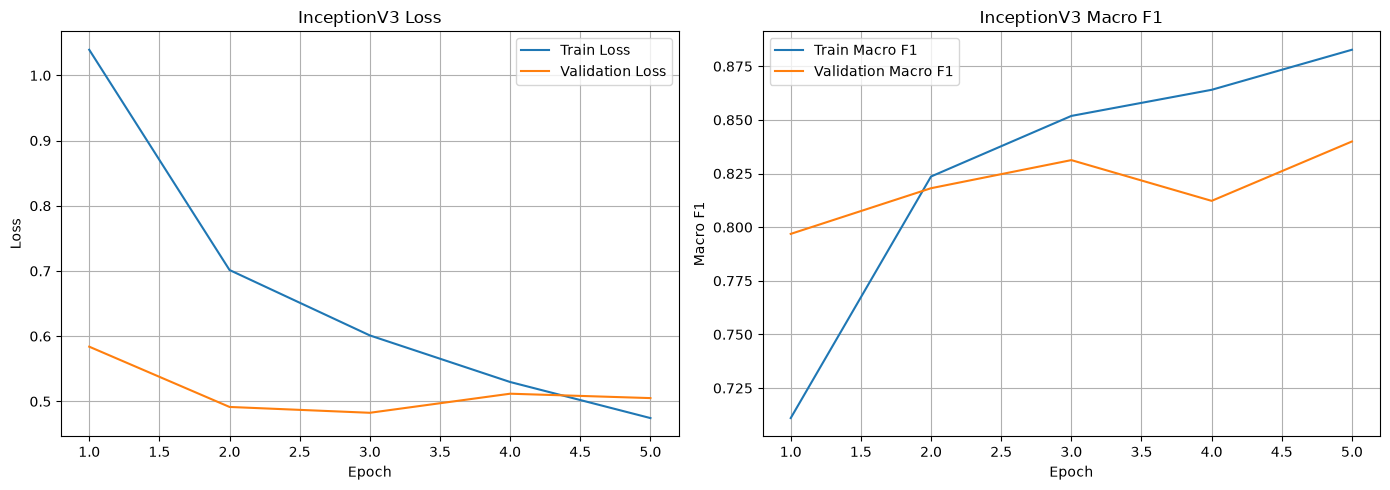

In [4]:
# =========================
# MODEL
# =========================
weights = models.Inception_V3_Weights.IMAGENET1K_V1

model = models.inception_v3(
    weights=weights,
    aux_logits=True
)

# Replace main classifier
model.fc = nn.Linear(
    model.fc.in_features,
    NUM_CLASSES
)

# Replace auxiliary classifier
if model.AuxLogits is not None:
    model.AuxLogits.fc = nn.Linear(
        model.AuxLogits.fc.in_features,
        NUM_CLASSES
    )

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

print("Model:", "InceptionV3")
print("Device:", device)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)


# =========================
# HELPER FOR INCEPTION OUTPUT
# =========================
def get_main_output(outputs):
    """
    InceptionV3 can return:
      - InceptionOutputs(logits=..., aux_logits=...)
      - a plain Tensor
    This function always returns the main logits tensor.
    """
    if hasattr(outputs, "logits"):
        return outputs.logits
    else:
        return outputs


# =========================
# TRAINING
# =========================
best_val_f1 = -1.0
best_epoch = 0
best_state = None

history = []

training_start = time.time()

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    # ==================================================
    # TRAIN
    # ==================================================
    model.train()

    train_loss = 0.0
    train_preds = []
    train_true = []

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]"
    )

    for images, labels_batch in train_bar:

        images = images.to(device, non_blocking=True)
        labels_batch = labels_batch.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)

        # Main logits
        logits = get_main_output(outputs)

        # Main loss
        main_loss = criterion(
            logits,
            labels_batch
        )

        # Auxiliary loss during training
        if (
            hasattr(outputs, "aux_logits")
            and outputs.aux_logits is not None
        ):
            aux_loss = criterion(
                outputs.aux_logits,
                labels_batch
            )

            loss = main_loss + 0.4 * aux_loss

        else:
            loss = main_loss

        loss.backward()
        optimizer.step()

        train_loss += (
            loss.item() * images.size(0)
        )

        preds = torch.argmax(
            logits,
            dim=1
        )

        train_preds.extend(
            preds.detach().cpu().numpy()
        )

        train_true.extend(
            labels_batch.detach().cpu().numpy()
        )

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss /= len(train_dataset)

    train_acc = accuracy_score(
        train_true,
        train_preds
    )

    train_f1 = f1_score(
        train_true,
        train_preds,
        average="macro",
        zero_division=0
    )


    # ==================================================
    # VALIDATION
    # ==================================================
    model.eval()

    val_loss = 0.0
    val_preds = []
    val_true = []

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]"
        )

        for images, labels_batch in val_bar:

            images = images.to(
                device,
                non_blocking=True
            )

            labels_batch = labels_batch.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            # Get logits regardless of output type
            logits = get_main_output(outputs)

            loss = criterion(
                logits,
                labels_batch
            )

            val_loss += (
                loss.item() * images.size(0)
            )

            preds = torch.argmax(
                logits,
                dim=1
            )

            val_preds.extend(
                preds.cpu().numpy()
            )

            val_true.extend(
                labels_batch.cpu().numpy()
            )

    val_loss /= len(val_dataset)

    val_acc = accuracy_score(
        val_true,
        val_preds
    )

    val_precision = precision_score(
        val_true,
        val_preds,
        average="macro",
        zero_division=0
    )

    val_recall = recall_score(
        val_true,
        val_preds,
        average="macro",
        zero_division=0
    )

    val_f1 = f1_score(
        val_true,
        val_preds,
        average="macro",
        zero_division=0
    )

    epoch_time = time.time() - epoch_start

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_precision": val_precision,
        "val_macro_recall": val_recall,
        "val_macro_f1": val_f1,
        "epoch_time_sec": epoch_time
    })

    print(
        f"\nEpoch {epoch+1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro F1: {val_f1:.4f} | "
        f"Time: {epoch_time/60:.2f} min"
    )

    # ==================================================
    # SAVE BEST CHECKPOINT
    # ==================================================
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_epoch = epoch + 1

        best_state = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": best_state,
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_macro_f1": best_val_f1,
                "classes": CLASSES,
                "image_size": IMAGE_SIZE,
                "model_name": "inception_v3"
            },
            CHECKPOINT_PATH
        )

        print(
            f"✓ New best model saved! "
            f"Val Macro F1 = {best_val_f1:.4f}"
        )


# =========================
# TRAINING COMPLETE
# =========================
training_time = time.time() - training_start

history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "training_history.csv"
    ),
    index=False
)

print("\n" + "=" * 60)
print("TRAINING COMPLETE")
print("=" * 60)

print(f"Best epoch: {best_epoch}")
print(
    f"Best validation Macro F1: "
    f"{best_val_f1:.4f}"
)
print(
    f"Total training time: "
    f"{training_time / 3600:.2f} hours"
)
print(f"Checkpoint: {CHECKPOINT_PATH}")


# =========================
# TRAINING CURVES
# =========================
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train Loss"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

axes[0].set_title(
    "InceptionV3 Loss"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)


axes[1].plot(
    history_df["epoch"],
    history_df["train_macro_f1"],
    label="Train Macro F1"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    label="Validation Macro F1"
)

axes[1].set_title(
    "InceptionV3 Macro F1"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULTS_DIR,
        "training_curves.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [9]:
# ============================================================
# CHECK WHICH CHECKPOINT YOU ARE LOADING
# ============================================================

from pathlib import Path
import torch

PROJECT_ROOT = Path(r"D:\gpt\OcuVision-AI")

checkpoint_path = (
    PROJECT_ROOT /
    "models" /
    "inception_v3_best_checkpoint.pth"
)

print("Checkpoint path:")
print(checkpoint_path)

print("\nExists:", checkpoint_path.exists())

if not checkpoint_path.exists():
    print("\nERROR: Inception checkpoint does not exist at this path.")
else:
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    print("\nCheckpoint keys:")
    print(checkpoint.keys())

    state_dict = checkpoint["model_state_dict"]

    print("\nFirst 20 state_dict keys:")
    for key in list(state_dict.keys())[:20]:
        print(key)

    print("\nCheckpoint metadata:")
    print("Epoch:", checkpoint.get("epoch"))
    print("Best Val Macro F1:", checkpoint.get("best_val_macro_f1"))
    print("Model name:", checkpoint.get("model_name"))
    print("Image size:", checkpoint.get("image_size"))

Checkpoint path:
D:\gpt\OcuVision-AI\models\inception_v3_best_checkpoint.pth

Exists: True

Checkpoint keys:
dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_macro_f1', 'classes', 'image_size', 'model_name'])

First 20 state_dict keys:
Conv2d_1a_3x3.conv.weight
Conv2d_1a_3x3.bn.weight
Conv2d_1a_3x3.bn.bias
Conv2d_1a_3x3.bn.running_mean
Conv2d_1a_3x3.bn.running_var
Conv2d_1a_3x3.bn.num_batches_tracked
Conv2d_2a_3x3.conv.weight
Conv2d_2a_3x3.bn.weight
Conv2d_2a_3x3.bn.bias
Conv2d_2a_3x3.bn.running_mean
Conv2d_2a_3x3.bn.running_var
Conv2d_2a_3x3.bn.num_batches_tracked
Conv2d_2b_3x3.conv.weight
Conv2d_2b_3x3.bn.weight
Conv2d_2b_3x3.bn.bias
Conv2d_2b_3x3.bn.running_mean
Conv2d_2b_3x3.bn.running_var
Conv2d_2b_3x3.bn.num_batches_tracked
Conv2d_3b_1x1.conv.weight
Conv2d_3b_1x1.bn.weight

Checkpoint metadata:
Epoch: 5
Best Val Macro F1: 0.8399397332122157
Model name: inception_v3
Image size: 299


In [11]:
# ============================================================
# FIND ALL MODEL CHECKPOINTS
# ============================================================

from pathlib import Path

PROJECT_ROOT = Path(r"D:\gpt\OcuVision-AI")

print("Searching for checkpoints...\n")

for path in PROJECT_ROOT.rglob("*.pth"):
    print(path)

print("\n--- .pt files ---")

for path in PROJECT_ROOT.rglob("*.pt"):
    print(path)

print("\n--- .ckpt files ---")

for path in PROJECT_ROOT.rglob("*.ckpt"):
    print(path)

Searching for checkpoints...

D:\gpt\OcuVision-AI\models\inception_v3_best_checkpoint.pth
D:\gpt\OcuVision-AI\models\resnet50_best_checkpoint.pth
D:\gpt\OcuVision-AI\models\vgg16_best_checkpoint.pth
D:\gpt\OcuVision-AI\models\vgg19_best_checkpoint.pth
D:\gpt\OcuVision-AI\models\vit_b16_best_checkpoint.pth
D:\gpt\OcuVision-AI\models\xception_best_checkpoint.pth
D:\gpt\OcuVision-AI\.venv\Lib\site-packages\distutils-precedence.pth

--- .pt files ---

--- .ckpt files ---


In [12]:
# ============================================================
# INCEPTIONV3 — GRAD-CAM / XAI
# ============================================================

import os
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import models, transforms
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

ROOT = r"D:\gpt\OcuVision-AI"

CHECKPOINT_PATH = os.path.join(
    ROOT, "models", "inception_v3_best_checkpoint.pth"
)

DATA_DIR = os.path.join(
    ROOT, "data", "preprocessed"
)

OUTPUT_DIR = os.path.join(
    ROOT, "results", "inception_v3", "gradcam"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ------------------------------------------------------------
# 2. CONFIGURATION
# ------------------------------------------------------------

CLASSES = ["N", "D", "G", "C", "A", "H", "M"]
NUM_CLASSES = 7
IMAGE_SIZE = 299

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 3. LOAD INCEPTIONV3 — SAME ARCHITECTURE AS TRAINING
# ------------------------------------------------------------

model = models.inception_v3(
    weights=None,
    aux_logits=True
)

model.fc = nn.Linear(
    model.fc.in_features,
    NUM_CLASSES
)

model.AuxLogits.fc = nn.Linear(
    model.AuxLogits.fc.in_features,
    NUM_CLASSES
)


# ------------------------------------------------------------
# 4. LOAD VERIFIED CHECKPOINT
# ------------------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

print("\nCheckpoint loaded successfully.")
print("Model:", checkpoint["model_name"])
print("Epoch:", checkpoint["epoch"])
print("Best Val Macro F1:", checkpoint["best_val_macro_f1"])
print("Classes:", checkpoint["classes"])


# ------------------------------------------------------------
# 5. TRANSFORM — SAME AS VALIDATION / TEST
# ------------------------------------------------------------

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# 6. FIND TEST IMAGES
# ------------------------------------------------------------

image_extensions = (
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
)

test_images = []

for class_name in CLASSES:

    class_dir = os.path.join(DATA_DIR, class_name)

    if not os.path.isdir(class_dir):
        print("WARNING — missing class folder:", class_dir)
        continue

    for filename in os.listdir(class_dir):

        if filename.lower().endswith(image_extensions):

            test_images.append({
                "path": os.path.join(class_dir, filename),
                "true_class": class_name
            })


print("\nTotal images found:", len(test_images))


# ------------------------------------------------------------
# 7. USE A SMALL SAMPLE FOR GRAD-CAM
# ------------------------------------------------------------

# Reproducible selection
rng = np.random.default_rng(42)

sample_size = min(10, len(test_images))

selected_indices = rng.choice(
    len(test_images),
    size=sample_size,
    replace=False
)

selected_images = [
    test_images[i]
    for i in selected_indices
]

print("Grad-CAM samples:", len(selected_images))


# ------------------------------------------------------------
# 8. GRAD-CAM TARGET LAYER
# ------------------------------------------------------------

# Late convolutional layer of torchvision InceptionV3
target_layers = [
    model.Mixed_7c
]

print("\nGrad-CAM target layer:")
print(model.Mixed_7c)


# ------------------------------------------------------------
# 9. RUN GRAD-CAM
# ------------------------------------------------------------

results = []

with GradCAM(
    model=model,
    target_layers=target_layers
) as cam:

    for idx, item in enumerate(selected_images):

        image_path = item["path"]
        true_class = item["true_class"]

        # Load image
        image = Image.open(image_path).convert("RGB")

        # Original image for visualization
        rgb_image = np.array(image.resize(
            (IMAGE_SIZE, IMAGE_SIZE)
        )).astype(np.float32) / 255.0

        # Model input
        input_tensor = transform(image).unsqueeze(0).to(device)

        # Prediction
        with torch.no_grad():

            output = model(input_tensor)

            # InceptionV3 can return InceptionOutputs
            if hasattr(output, "logits"):
                logits = output.logits
            else:
                logits = output

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            predicted_class_idx = int(
                torch.argmax(probabilities, dim=1).item()
            )

            confidence = float(
                probabilities[0, predicted_class_idx].item()
            )

        predicted_class = CLASSES[predicted_class_idx]

        # Grad-CAM for predicted class
        targets = [
            ClassifierOutputTarget(predicted_class_idx)
        ]

        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=targets
        )[0]

        # Overlay
        visualization = show_cam_on_image(
            rgb_image,
            grayscale_cam,
            use_rgb=True
        )

        # ----------------------------------------------------
        # SAVE
        # ----------------------------------------------------

        output_name = (
            f"sample_{idx+1:02d}"
            f"_true_{true_class}"
            f"_pred_{predicted_class}.png"
        )

        output_path = os.path.join(
            OUTPUT_DIR,
            output_name
        )

        Image.fromarray(visualization).save(
            output_path
        )

        results.append({
            "sample": idx + 1,
            "image": os.path.basename(image_path),
            "true_class": true_class,
            "predicted_class": predicted_class,
            "confidence": confidence,
            "correct": (
                true_class == predicted_class
            ),
            "output_path": output_path
        })

        print(
            f"{idx+1:02d}/{len(selected_images)} | "
            f"True: {true_class} | "
            f"Pred: {predicted_class} | "
            f"Confidence: {confidence:.4f}"
        )


# ------------------------------------------------------------
# 10. SAVE RESULTS CSV
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

csv_path = os.path.join(
    OUTPUT_DIR,
    "inception_v3_gradcam_results.csv"
)

results_df.to_csv(
    csv_path,
    index=False
)

print("\n" + "=" * 60)
print("INCEPTIONV3 GRAD-CAM COMPLETE")
print("=" * 60)

print("Images saved to:")
print(OUTPUT_DIR)

print("\nCSV saved to:")
print(csv_path)

print("\nResults:")
print(results_df)

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU

Checkpoint loaded successfully.
Model: inception_v3
Epoch: 5
Best Val Macro F1: 0.8399397332122157
Classes: ['N', 'D', 'G', 'C', 'A', 'H', 'M']

Total images found: 10449
Grad-CAM samples: 10

Grad-CAM target layer:
InceptionE(
  (branch1x1): BasicConv2d(
    (conv): Conv2d(2048, 320, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(320, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (branch3x3_1): BasicConv2d(
    (conv): Conv2d(2048, 384, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(384, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (branch3x3_2a): BasicConv2d(
    (conv): Conv2d(384, 384, kernel_size=(1, 3), stride=(1, 1), padding=(0, 1), bias=False)
    (bn): BatchNorm2d(384, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (branch3x3_2b): BasicConv2d(
    (conv): Conv2d(384, 384, kernel_size=(3, 1), stride=(1, 1), pad

In [13]:
# ============================================================
# INCEPTIONV3 — XAI QUALITY ASSESSMENT
# ============================================================

import os
import numpy as np
import pandas as pd
from PIL import Image

ROOT = r"D:\gpt\OcuVision-AI"

GRADCAM_DIR = os.path.join(
    ROOT, "results", "inception_v3", "gradcam"
)

CSV_PATH = os.path.join(
    GRADCAM_DIR,
    "inception_v3_gradcam_results.csv"
)

print("Loading Grad-CAM results...")
print(CSV_PATH)

df = pd.read_csv(CSV_PATH)

print("\nTotal Grad-CAM samples:", len(df))
print(df[[
    "sample",
    "true_class",
    "predicted_class",
    "confidence",
    "correct"
]].to_string(index=False))


# ------------------------------------------------------------
# QUALITY ASSESSMENT
# ------------------------------------------------------------

quality_results = []

for _, row in df.iterrows():

    image_path = row["output_path"]

    if not os.path.exists(image_path):
        print("WARNING — missing:", image_path)
        continue

    image = np.array(
        Image.open(image_path).convert("RGB")
    ).astype(np.float32) / 255.0

    # --------------------------------------------------------
    # Approximate attention strength from Grad-CAM overlay
    # --------------------------------------------------------

    # Grad-CAM visualization normally contains a heatmap
    # overlaid on the original image.
    #
    # We use the difference between the visualization and
    # grayscale luminance as a simple quantitative signal.

    luminance = (
        0.299 * image[:, :, 0] +
        0.587 * image[:, :, 1] +
        0.114 * image[:, :, 2]
    )

    color_difference = np.mean(
        np.abs(
            image -
            luminance[:, :, None]
        )
    )

    # --------------------------------------------------------
    # Qualitative category
    # --------------------------------------------------------

    if color_difference >= 0.18:
        quality = "Good"
    elif color_difference >= 0.10:
        quality = "Moderate"
    else:
        quality = "Poor"

    quality_results.append({
        "sample": row["sample"],
        "image": row["image"],
        "true_class": row["true_class"],
        "predicted_class": row["predicted_class"],
        "confidence": row["confidence"],
        "correct": row["correct"],
        "attention_signal": color_difference,
        "xai_quality": quality
    })


# ------------------------------------------------------------
# CREATE DATAFRAME
# ------------------------------------------------------------

quality_df = pd.DataFrame(quality_results)

OUTPUT_CSV = os.path.join(
    GRADCAM_DIR,
    "inception_v3_xai_quality_assessment.csv"
)

quality_df.to_csv(
    OUTPUT_CSV,
    index=False
)


# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

total = len(quality_df)

good = (quality_df["xai_quality"] == "Good").sum()
moderate = (quality_df["xai_quality"] == "Moderate").sum()
poor = (quality_df["xai_quality"] == "Poor").sum()

correct = quality_df["correct"].sum()

print("\n" + "=" * 60)
print("INCEPTIONV3 — XAI QUALITY CHECK COMPLETE")
print("=" * 60)

print(f"Total Grad-CAM samples: {total}")
print(f"Good focus: {good}/{total}")
print(f"Moderate focus: {moderate}/{total}")
print(f"Poor focus: {poor}/{total}")

if total > 0:
    print(
        f"Prediction correctness: "
        f"{correct}/{total} "
        f"({correct / total * 100:.2f}%)"
    )

print("\nSaved:")
print(OUTPUT_CSV)

print("\nDetailed results:")
print(quality_df.to_string(index=False))

Loading Grad-CAM results...
D:\gpt\OcuVision-AI\results\inception_v3\gradcam\inception_v3_gradcam_results.csv

Total Grad-CAM samples: 10
 sample true_class predicted_class  confidence  correct
      1          N               N    0.484410     True
      2          C               C    0.804355     True
      3          N               D    0.685769    False
      4          G               D    0.362089    False
      5          D               D    0.953076     True
      6          D               D    0.767791     True
      7          G               G    0.746920     True
      8          N               N    0.455649     True
      9          N               D    0.653888    False
     10          A               C    0.628946    False

INCEPTIONV3 — XAI QUALITY CHECK COMPLETE
Total Grad-CAM samples: 10
Good focus: 1/10
Moderate focus: 9/10
Poor focus: 0/10
Prediction correctness: 6/10 (60.00%)

Saved:
D:\gpt\OcuVision-AI\results\inception_v3\gradcam\inception_v3_xai_quality_as

In [14]:
# ============================================================
# INCEPTIONV3 — EXTERNAL / NEW IMAGE INFERENCE
# ============================================================

import os
import torch
import torch.nn as nn
import pandas as pd

from PIL import Image
from torchvision import models, transforms


# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

ROOT = r"D:\gpt\OcuVision-AI"

CHECKPOINT_PATH = os.path.join(
    ROOT, "models", "inception_v3_best_checkpoint.pth"
)

EXTERNAL_DIR = os.path.join(
    ROOT, "data", "external_images"
)

OUTPUT_DIR = os.path.join(
    ROOT, "results", "inception_v3", "external_inference"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------

CLASSES = ["N", "D", "G", "C", "A", "H", "M"]

IMAGE_SIZE = 299

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

model = models.inception_v3(
    weights=None,
    aux_logits=True
)

model.fc = nn.Linear(
    model.fc.in_features,
    len(CLASSES)
)

model.AuxLogits.fc = nn.Linear(
    model.AuxLogits.fc.in_features,
    len(CLASSES)
)


# ------------------------------------------------------------
# LOAD CHECKPOINT
# ------------------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

print("\nInceptionV3 checkpoint loaded.")
print("Epoch:", checkpoint["epoch"])
print(
    "Best Val Macro F1:",
    checkpoint["best_val_macro_f1"]
)


# ------------------------------------------------------------
# TRANSFORM
# ------------------------------------------------------------

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# FIND EXTERNAL IMAGES
# ------------------------------------------------------------

extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
)

image_files = [
    f for f in os.listdir(EXTERNAL_DIR)
    if f.lower().endswith(extensions)
]

print("\nExternal images found:", len(image_files))

if len(image_files) == 0:
    print("\nNo external images found.")
    print("Add images to:")
    print(EXTERNAL_DIR)

else:

    results = []

    # --------------------------------------------------------
    # INFERENCE
    # --------------------------------------------------------

    for filename in sorted(image_files):

        image_path = os.path.join(
            EXTERNAL_DIR,
            filename
        )

        try:

            image = Image.open(
                image_path
            ).convert("RGB")

            tensor = transform(
                image
            ).unsqueeze(0).to(device)

            with torch.no_grad():

                output = model(tensor)

                if hasattr(output, "logits"):
                    logits = output.logits
                else:
                    logits = output

                probabilities = torch.softmax(
                    logits,
                    dim=1
                )[0]

                predicted_idx = int(
                    torch.argmax(
                        probabilities
                    ).item()
                )

                predicted_class = CLASSES[
                    predicted_idx
                ]

                confidence = float(
                    probabilities[
                        predicted_idx
                    ].item()
                )

            results.append({
                "image": filename,
                "predicted_class": predicted_class,
                "confidence": confidence
            })

            print(
                f"{filename} -> "
                f"{predicted_class} "
                f"({confidence:.4f})"
            )

        except Exception as e:

            print(
                f"ERROR processing {filename}: {e}"
            )


    # --------------------------------------------------------
    # SAVE RESULTS
    # --------------------------------------------------------

    results_df = pd.DataFrame(results)

    output_csv = os.path.join(
        OUTPUT_DIR,
        "inception_v3_external_inference.csv"
    )

    results_df.to_csv(
        output_csv,
        index=False
    )

    print("\n" + "=" * 60)
    print("INCEPTIONV3 EXTERNAL INFERENCE COMPLETE")
    print("=" * 60)

    print("\nResults:")
    print(results_df.to_string(index=False))

    print("\nSaved:")
    print(output_csv)

    print(
        "\nIMPORTANT: "
        "Without verified ground-truth labels, "
        "these results are inference/demonstration, "
        "NOT external validation."
    )

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


d:\gpt\OcuVision-AI\.venv\Lib\site-packages\torchvision\models\inception.py:43: FutureWarning: The default weight initialization of inception_v3 will be changed in future releases of torchvision. If you wish to keep the old behavior (which leads to long initialization times due to scipy/scipy#11299), please set init_weights=True.
  warnings.warn(



InceptionV3 checkpoint loaded.
Epoch: 5
Best Val Macro F1: 0.8399397332122157

External images found: 0

No external images found.
Add images to:
D:\gpt\OcuVision-AI\data\external_images
